# Sberbank Russian Housing Market — поверхностный EDA

**Задача соревнования:** предсказать цену квартиры в Москве (`price_doc`).
**Данные:** `train.csv` (сделки 2011–2015) и `macro.csv` (макроэкономика по дням).

План:
1. Загрузка данных
2. Первый взгляд
2.1. Что значат колонки (словарь)
2.2. Переименовываем колонки на русский
3. Пропуски
4. Целевая переменная
5. Ключевые признаки
6. Ошибки и выбросы
7. Цена во времени
8. Корреляции с ценой
9. Районы
10. Макроэкономика
11. Выводы

## Шаг 0. Импорты

In [56]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option('display.max_columns', 50)
sns.set_theme(style='whitegrid')
plt.rcParams['figure.figsize'] = (10, 4)

## Шаг 1. Загрузка данных

In [57]:
BASE_URL = 'https://raw.githubusercontent.com/TomGeva/ML-project/main/'
train = pd.read_csv(BASE_URL + 'train.csv', parse_dates=['timestamp'])
macro = pd.read_csv(BASE_URL + 'macro.csv', parse_dates=['timestamp'])

print('train:', train.shape)
print('macro:', macro.shape)

train: (30471, 292)
macro: (2484, 100)


## Шаг 2. Первый взгляд

In [58]:
train.head()

,id,timestamp,full_sq,life_sq,floor,max_floor,material,build_year,num_room,kitch_sq,state,product_type,sub_area,area_m,raion_popul,green_zone_part,indust_part,children_preschool,preschool_quota,preschool_education_centers_raion,children_school,school_quota,school_education_centers_raion,school_education_centers_top_20_raion,hospital_beds_raion,...,market_count_3000,green_part_5000,prom_part_5000,office_count_5000,office_sqm_5000,trc_count_5000,trc_sqm_5000,cafe_count_5000,cafe_sum_5000_min_price_avg,cafe_sum_5000_max_price_avg,cafe_avg_price_5000,cafe_count_5000_na_price,cafe_count_5000_price_500,cafe_count_5000_price_1000,cafe_count_5000_price_1500,cafe_count_5000_price_2500,cafe_count_5000_price_4000,cafe_count_5000_price_high,big_church_count_5000,church_count_5000,mosque_count_5000,leisure_count_5000,sport_count_5000,market_count_5000,price_doc
0,1,2011-08-20,43,27.0,4.0,NaN,NaN,NaN,NaN,NaN,NaN,Investment,Bibirevo,6.407578e+06,155572,0.189727,0.000070,9576,5001.0,5,10309,11065.0,5,0,240.0,...,1,13.09,13.31,29,807385,52,4036616,152,708.57,1185.71,947.14,12,39,48,40,9,4,0,13,22,1,0,52,4,5850000
1,2,2011-08-23,34,19.0,3.0,NaN,NaN,NaN,NaN,NaN,NaN,Investment,Nagatinskij Zaton,9.589337e+06,115352,0.372602,0.049637,6880,3119.0,5,7759,6237.0,8,0,229.0,...,1,10.26,27.47,66,2690465,40,2034942,177,673.81,1148.81,911.31,9,49,65,36,15,3,0,15,29,1,10,66,14,6000000
2,3,2011-08-27,43,29.0,2.0,NaN,NaN,NaN,NaN,NaN,NaN,Investment,Tekstil'shhiki,4.808270e+06,101708,0.112560,0.118537,5879,1463.0,4,6207,5580.0,7,0,1183.0,...,6,13.69,21.58,43,1478160,35,1572990,122,702.68,1196.43,949.55,10,29,45,25,10,3,0,11,27,0,4,67,10,5700000
3,4,2011-09-01,89,50.0,9.0,NaN,NaN,NaN,NaN,NaN,NaN,Investment,Mitino,1.258354e+07,178473,0.194703,0.069753,13087,6839.0,9,13670,17063.0,10,0,NaN,...,3,14.18,3.89,8,244166,22,942180,61,931.58,1552.63,1242.11,4,7,21,15,11,2,1,4,4,0,0,26,3,13100000
4,5,2011-09-05,77,77.0,4.0,NaN,NaN,NaN,NaN,NaN,NaN,Investment,Basmannoe,8.398461e+06,108171,0.015234,0.037316,5706,3240.0,7,6748,7770.0,9,0,562.0,...,5,8.38,10.92,689,8404624,114,3503058,2283,853.88,1411.45,1132.66,143,566,578,552,319,108,17,135,236,2,91,195,14,16331452


In [59]:
# Типы колонок
train.dtypes.value_counts()

int64             157
float64           119
str                15
datetime64[us]      1
Name: count, dtype: int64

In [60]:
# Текстовые (категориальные) колонки и сколько у них уникальных значений
train.select_dtypes(exclude=['number', 'datetime']).nunique().sort_values(ascending=False)

sub_area                     146
ecology                        5
product_type                   2
thermal_power_plant_raion      2
incineration_raion             2
oil_chemistry_raion            2
culture_objects_top_25         2
radiation_raion                2
railroad_terminal_raion        2
nuclear_reactor_raion          2
big_market_raion               2
detention_facility_raion       2
water_1line                    2
big_road1_1line                2
railroad_1line                 2
dtype: int64

In [61]:
# Основные признаки квартиры
main_cols = ['full_sq', 'life_sq', 'kitch_sq', 'floor', 'max_floor',
             'num_room', 'build_year', 'state', 'material', 'price_doc']
train[main_cols].describe().T.round(1)

,count,mean,std,min,25%,50%,75%,max
full_sq,30471.0,54.2,38.0,0.0,38.0,49.0,63.0,5326.0
life_sq,24088.0,34.4,52.3,0.0,20.0,30.0,43.0,7478.0
kitch_sq,20899.0,6.4,28.3,0.0,1.0,6.0,9.0,2014.0
floor,30304.0,7.7,5.3,0.0,3.0,6.5,11.0,77.0
max_floor,20899.0,12.6,6.8,0.0,9.0,12.0,17.0,117.0
num_room,20899.0,1.9,0.9,0.0,1.0,2.0,2.0,19.0
build_year,16866.0,3068.1,154387.8,0.0,1967.0,1979.0,2005.0,20052009.0
state,16912.0,2.1,0.9,1.0,1.0,2.0,3.0,33.0
material,20899.0,1.8,1.5,1.0,1.0,1.0,2.0,6.0
price_doc,30471.0,7123035.3,4780111.3,100000.0,4740002.0,6274411.0,8300000.0,111111112.0


## Шаг 2.1. Что значат колонки

В `train.csv` 292 колонки. Их можно разбить на 6 групп:

| Группа | Колонок | Что внутри |
|---|---|---|
| 1. Квартира и сделка | 14 | площадь, этаж, комнаты, год постройки, **цена** |
| 2. Район: инфраструктура | 34 | школы, больницы, ТЦ, промзоны, «вредные» объекты |
| 3. Район: демография | 24 | сколько людей какого возраста и пола |
| 4. Район: типы домов | 14 | сколько панельных, кирпичных, старых, новых домов |
| 5. Расстояния | 68 | км/минуты до метро, центра, парка, МКАД и т.д. |
| 6. В радиусе N метров | 138 | сколько кафе, ТЦ, офисов, спортобъектов рядом |

### Главные колонки (про саму квартиру)

| Колонка | Значение |
|---|---|
| `price_doc` | **Цена квартиры, ₽ — это мы предсказываем** |
| `timestamp` | Дата сделки |
| `full_sq` | Общая площадь, м² (с балконами) |
| `life_sq` | Жилая площадь, м² |
| `kitch_sq` | Площадь кухни, м² |
| `floor` / `max_floor` | Этаж квартиры / всего этажей в доме |
| `num_room` | Число комнат |
| `build_year` | Год постройки |
| `material` | Материал стен (код 1–6) |
| `state` | Состояние (1 — плохое … 4 — отличное) |
| `product_type` | `Investment` — купили для инвестиций, `OwnerOccupier` — для себя (часто новостройка) |
| `sub_area` | Район Москвы |

### Как читать остальные названия

Большинство колонок собраны по шаблону, поэтому достаточно знать «кусочки»:

- `*_km` — расстояние в км до объекта (`kremlin_km` — до Кремля, `park_km` — до парка)
- `*_min_walk` / `*_avto` — пешком / на машине
- `*_raion` — показатель по всему району
- `*_1line` — «первая линия» (дом прямо у реки/дороги/ж/д)
- `ID_*` — номер ближайшего объекта (это код, не число)
- `X_count_500` — сколько объектов X в радиусе 500 м (бывает 500, 1000, 1500, 2000, 3000, 5000)
- `X_part_500` — какая доля территории в радиусе 500 м занята X
- `cafe_count_1000_price_1500` — кафе в радиусе 1000 м со средним чеком 1000–1500 ₽
- `trc` — торговые центры, `prom` — промзоны, `green` — зелёные зоны
- `mkad` — МКАД, `ttk` — ТТК, `sadovoe` — Садовое кольцо, `bulvar_ring` — Бульварное кольцо
- `young` / `work` / `ekder` — дети / трудоспособные / пенсионеры
- `0_6_all`, `7_14_male`… — население этого возраста (все / мужчины / женщины)

Ниже — полный словарь всех 292 колонок на русском. Он собирается автоматически по этим правилам.

In [62]:
# Словарь колонок на русском + функции explain(col) и ru_name(col)
import re

# Колонки, которые объясняем по отдельности
COLS_RU = {
    # --- Квартира и сделка ---
    'id': 'ID сделки',
    'timestamp': 'Дата сделки',
    'price_doc': 'ЦЕНА квартиры, ₽ (целевая переменная)',
    'full_sq': 'Общая площадь, м² (с балконами и лоджиями)',
    'life_sq': 'Жилая площадь, м² (без балконов, кухни и т.п.)',
    'kitch_sq': 'Площадь кухни, м²',
    'floor': 'Этаж квартиры',
    'max_floor': 'Сколько всего этажей в доме',
    'material': 'Материал стен (код 1–6, расшифровки нет)',
    'build_year': 'Год постройки дома',
    'num_room': 'Число жилых комнат',
    'state': 'Состояние квартиры (1 — плохое … 4 — отличное)',
    'product_type': 'Тип сделки: Investment (покупка для инвестиций) / OwnerOccupier (для себя, часто новостройка)',
    'sub_area': 'Район Москвы',
    # --- Район: общее ---
    'area_m': 'Площадь района, м²',
    'raion_popul': 'Население района',
    'green_zone_part': 'Доля зелёных зон в районе',
    'indust_part': 'Доля промзон в районе',
    'children_preschool': 'Детей дошкольного возраста в районе',
    'preschool_quota': 'Мест в детсадах района',
    'preschool_education_centers_raion': 'Число детсадов в районе',
    'children_school': 'Детей школьного возраста в районе',
    'school_quota': 'Мест в школах района',
    'school_education_centers_raion': 'Число школ в районе',
    'school_education_centers_top_20_raion': 'Школ из топ-20 Москвы в районе',
    'hospital_beds_raion': 'Больничных коек в районе',
    'healthcare_centers_raion': 'Поликлиник/медцентров в районе',
    'university_top_20_raion': 'Вузов из топ-рейтинга в районе',
    'sport_objects_raion': 'Спортивных объектов в районе',
    'additional_education_raion': 'Учреждений доп. образования в районе',
    'culture_objects_top_25': 'Есть ли в районе значимые объекты культурного наследия (yes/no)',
    'culture_objects_top_25_raion': 'Число объектов культурного наследия в районе',
    'shopping_centers_raion': 'Торговых центров в районе',
    'office_raion': 'Офисных центров в районе',
    'thermal_power_plant_raion': 'Есть ли ТЭЦ в районе (yes/no)',
    'incineration_raion': 'Есть ли мусоросжигательный завод (yes/no)',
    'oil_chemistry_raion': 'Есть ли «грязное» производство (yes/no)',
    'radiation_raion': 'Есть ли захоронение радиоактивных отходов (yes/no)',
    'railroad_terminal_raion': 'Есть ли ж/д вокзал (yes/no)',
    'big_market_raion': 'Есть ли крупный рынок (yes/no)',
    'nuclear_reactor_raion': 'Есть ли ядерный реактор (yes/no)',
    'detention_facility_raion': 'Есть ли СИЗО/тюрьма (yes/no)',
    'full_all': 'Население муниципалитета',
    'male_f': 'Мужчин в муниципалитете',
    'female_f': 'Женщин в муниципалитете',
    'ecology': 'Экологическая зона (excellent / good / satisfactory / poor / no data)',
    'raion_build_count_with_material_info': 'Зданий в районе, у которых известен материал',
    'raion_build_count_with_builddate_info': 'Зданий в районе, у которых известен год постройки',
    # --- Расстояния (особые) ---
    'metro_min_avto': 'Минут до метро на машине',
    'metro_km_avto': 'Км до метро на машине',
    'metro_min_walk': 'Минут до метро пешком',
    'metro_km_walk': 'Км до метро пешком',
    'railroad_station_walk_km': 'Км до ж/д станции пешком',
    'railroad_station_walk_min': 'Минут до ж/д станции пешком',
    'railroad_station_avto_km': 'Км до ж/д станции на машине',
    'railroad_station_avto_min': 'Минут до ж/д станции на машине',
    'public_transport_station_km': 'Км до остановки транспорта',
    'public_transport_station_min_walk': 'Минут пешком до остановки',
    'water_1line': 'Первая линия у реки (до 150 м, yes/no)',
    'big_road1_1line': 'Первая линия у крупной дороги (yes/no)',
    'railroad_1line': 'Первая линия у железной дороги (до 100 м, yes/no)',
    'mkad_km': 'Км до МКАД',
    'ttk_km': 'Км до ТТК (Третье транспортное кольцо)',
    'sadovoe_km': 'Км до Садового кольца',
    'bulvar_ring_km': 'Км до Бульварного кольца',
    'kremlin_km': 'Км до Кремля (центра города)',
    'zd_vokzaly_avto_km': 'Км до ж/д вокзала (на машине)',
    'bus_terminal_avto_km': 'Км до автовокзала (на машине)',
    'big_road1_km': 'Км до ближайшей крупной дороги',
    'big_road2_km': 'Км до второй ближайшей крупной дороги',
    'oil_chemistry_km': 'Км до «грязного» производства',
    'ts_km': 'Км до электростанции',
}

# Словарь для объектов в именах колонок
OBJ = {
    'kindergarten': 'детсада', 'school': 'школы', 'park': 'парка', 'green_zone': 'зелёной зоны',
    'industrial_zone': 'промзоны', 'industrial': 'промзоны', 'water_treatment': 'очистных сооружений', 'cemetery': 'кладбища',
    'incineration': 'мусоросжигательного завода', 'water': 'реки/водоёма', 'railroad': 'железной дороги',
    'nuclear_reactor': 'ядерного реактора', 'radiation': 'захоронения радиоотходов',
    'power_transmission_line': 'ЛЭП', 'thermal_power_plant': 'ТЭЦ', 'big_market': 'крупного рынка',
    'market_shop': 'рынков и универмагов', 'fitness': 'фитнеса', 'swim_pool': 'бассейна',
    'ice_rink': 'ледового дворца', 'stadium': 'стадиона', 'basketball': 'баскетбольной площадки',
    'hospice_morgue': 'хосписа/морга', 'detention_facility': 'СИЗО/тюрьмы',
    'public_healthcare': 'поликлиники', 'university': 'вуза', 'workplaces': 'рабочих мест',
    'shopping_centers': 'торгового центра', 'office': 'офисов', 'additional_education': 'доп. образования',
    'preschool': 'дошкольного учреждения', 'big_church': 'большой церкви',
    'church_synagogue': 'церкви/синагоги', 'mosque': 'мечети', 'theater': 'театра',
    'museum': 'музея', 'exhibition': 'выставки', 'catering': 'общепита',
}

AGE = {'young': 'младше трудоспособного возраста', 'work': 'трудоспособного возраста',
       'ekder': 'старше трудоспособного возраста (пенсионеры)', '0_6': '0–6 лет', '7_14': '7–14 лет',
       '0_17': '0–17 лет', '16_29': '16–29 лет', '0_13': '0–13 лет'}
SEX = {'all': 'все', 'male': 'мужчины', 'female': 'женщины'}
MAT = {'block': 'блочных', 'wood': 'деревянных', 'frame': 'каркасных', 'brick': 'кирпичных',
       'monolith': 'монолитных', 'panel': 'панельных', 'foam': 'пеноблочных', 'slag': 'шлакоблочных',
       'mix': 'смешанных', 'before_1920': 'до 1920 г.', '1921-1945': '1921–1945 гг.',
       '1946-1970': '1946–1970 гг.', '1971-1995': '1971–1995 гг.', 'after_1995': 'после 1995 г.'}
CNT = {'office': 'офисов', 'trc': 'торговых центров', 'cafe': 'кафе/ресторанов',
       'big_church': 'больших церквей', 'church': 'церквей', 'mosque': 'мечетей',
       'leisure': 'мест досуга', 'sport': 'спортобъектов', 'market': 'рынков'}
BILL = {'500': 'до 500 ₽', '1000': '500–1000 ₽', '1500': '1000–1500 ₽', '2500': '1500–2500 ₽',
        '4000': '2500–4000 ₽', 'high': 'больше 4000 ₽'}


def explain(col):
    """Возвращает (группа, объяснение) для колонки."""
    if col in COLS_RU:
        if col in ['id', 'timestamp', 'price_doc', 'full_sq', 'life_sq', 'kitch_sq', 'floor', 'max_floor',
                   'material', 'build_year', 'num_room', 'state', 'product_type', 'sub_area']:
            g = '1. Квартира и сделка'
        elif col.endswith(('_km', '_min', '_walk', '_avto', '1line')):
            g = '5. Расстояния'
        else:
            g = '2. Район: инфраструктура и население'
        return g, COLS_RU[col]
    if col.startswith('ID_'):
        return '5. Расстояния', 'ID ближайшего объекта (' + col[3:] + ') — просто номер, не число'
    m = re.fullmatch(r'(young|work|ekder|0_6|7_14|0_17|16_29|0_13)_(all|male|female)', col)
    if m:
        return '3. Район: демография', f'Население {AGE[m[1]]} ({SEX[m[2]]})'
    m = re.fullmatch(r'build_count_(.+)', col)
    if m:
        word = 'построенных ' if m[1][0].isdigit() or m[1].startswith(('before', 'after')) else ''
        return '4. Район: типы домов', f'Число {word}{MAT[m[1]]} домов в районе'
    m = re.fullmatch(r'(.+)_km', col)
    if m and m[1] in OBJ:
        return '5. Расстояния', f'Км до ближайшего {OBJ[m[1]]}'
    m = re.fullmatch(r'(green|prom)_part_(\d+)', col)
    if m:
        what = 'зелёных зон' if m[1] == 'green' else 'промзон'
        return '6. В радиусе N метров', f'Доля {what} в радиусе {m[2]} м'
    m = re.fullmatch(r'(office|trc)_sqm_(\d+)', col)
    if m:
        return '6. В радиусе N метров', f'Площадь {CNT[m[1]]} (м²) в радиусе {m[2]} м'
    m = re.fullmatch(r'cafe_count_(\d+)_price_(\w+)', col)
    if m:
        return '6. В радиусе N метров', f'Кафе со средним чеком {BILL[m[2]]} в радиусе {m[1]} м'
    m = re.fullmatch(r'cafe_count_(\d+)_na_price', col)
    if m:
        return '6. В радиусе N метров', f'Кафе без данных о чеке в радиусе {m[1]} м'
    m = re.fullmatch(r'cafe_sum_(\d+)_(min|max)_price_avg', col)
    if m:
        w = 'минимальный' if m[2] == 'min' else 'максимальный'
        return '6. В радиусе N метров', f'Средний {w} чек в кафе в радиусе {m[1]} м'
    m = re.fullmatch(r'cafe_avg_price_(\d+)', col)
    if m:
        return '6. В радиусе N метров', f'Средний чек в кафе в радиусе {m[1]} м'
    m = re.fullmatch(r'(\w+?)_count_(\d+)', col)
    if m and m[1] in CNT:
        return '6. В радиусе N метров', f'Число {CNT[m[1]]} в радиусе {m[2]} м'
    return '?', '—'


# ---------- Новые русские названия колонок ----------
RU_NAMES_FIXED = {
    'id': 'id_сделки', 'timestamp': 'дата', 'price_doc': 'цена',
    'full_sq': 'площадь_общая', 'life_sq': 'площадь_жилая', 'kitch_sq': 'площадь_кухни',
    'floor': 'этаж', 'max_floor': 'этажей_в_доме', 'material': 'материал_стен',
    'build_year': 'год_постройки', 'num_room': 'комнат', 'state': 'состояние',
    'product_type': 'тип_сделки', 'sub_area': 'район',
    'area_m': 'площадь_района', 'raion_popul': 'население_района',
    'green_zone_part': 'доля_зелени_в_районе', 'indust_part': 'доля_промзон_в_районе',
    'children_preschool': 'детей_дошкольников', 'preschool_quota': 'мест_в_детсадах',
    'preschool_education_centers_raion': 'детсадов_в_районе', 'children_school': 'детей_школьников',
    'school_quota': 'мест_в_школах', 'school_education_centers_raion': 'школ_в_районе',
    'school_education_centers_top_20_raion': 'топ20_школ_в_районе', 'hospital_beds_raion': 'коек_в_районе',
    'healthcare_centers_raion': 'поликлиник_в_районе', 'university_top_20_raion': 'топ_вузов_в_районе',
    'sport_objects_raion': 'спортобъектов_в_районе', 'additional_education_raion': 'доп_образования_в_районе',
    'culture_objects_top_25': 'есть_культурное_наследие', 'culture_objects_top_25_raion': 'объектов_культуры_в_районе',
    'shopping_centers_raion': 'тц_в_районе', 'office_raion': 'офисов_в_районе',
    'thermal_power_plant_raion': 'есть_тэц', 'incineration_raion': 'есть_мусоросжигатель',
    'oil_chemistry_raion': 'есть_грязное_производство', 'radiation_raion': 'есть_радиоотходы',
    'railroad_terminal_raion': 'есть_вокзал', 'big_market_raion': 'есть_крупный_рынок',
    'nuclear_reactor_raion': 'есть_ядерный_реактор', 'detention_facility_raion': 'есть_сизо',
    'full_all': 'население_муниципалитета', 'male_f': 'мужчин_в_муниципалитете', 'female_f': 'женщин_в_муниципалитете',
    'ecology': 'экология',
    'raion_build_count_with_material_info': 'домов_с_известным_материалом',
    'raion_build_count_with_builddate_info': 'домов_с_известным_годом',
    'metro_min_avto': 'мин_до_метро_авто', 'metro_km_avto': 'км_до_метро_авто',
    'metro_min_walk': 'мин_до_метро_пешком', 'metro_km_walk': 'км_до_метро_пешком',
    'railroad_station_walk_km': 'км_до_станции_пешком', 'railroad_station_walk_min': 'мин_до_станции_пешком',
    'railroad_station_avto_km': 'км_до_станции_авто', 'railroad_station_avto_min': 'мин_до_станции_авто',
    'public_transport_station_km': 'км_до_остановки', 'public_transport_station_min_walk': 'мин_до_остановки_пешком',
    'water_1line': 'первая_линия_река', 'big_road1_1line': 'первая_линия_дорога', 'railroad_1line': 'первая_линия_жд',
    'mkad_km': 'км_до_мкад', 'ttk_km': 'км_до_ттк', 'sadovoe_km': 'км_до_садового_кольца',
    'bulvar_ring_km': 'км_до_бульварного_кольца', 'kremlin_km': 'км_до_кремля',
    'zd_vokzaly_avto_km': 'км_до_вокзала', 'bus_terminal_avto_km': 'км_до_автовокзала',
    'big_road1_km': 'км_до_дороги_1', 'big_road2_km': 'км_до_дороги_2',
    'oil_chemistry_km': 'км_до_грязного_производства', 'ts_km': 'км_до_электростанции',
    'ID_metro': 'id_метро', 'ID_railroad_station_walk': 'id_станции_пешком', 'ID_railroad_station_avto': 'id_станции_авто',
    'ID_big_road1': 'id_дороги_1', 'ID_big_road2': 'id_дороги_2', 'ID_railroad_terminal': 'id_вокзала',
    'ID_bus_terminal': 'id_автовокзала',
}
_AGE_RU = {'young': 'моложе_трудоспособных', 'work': 'трудоспособных', 'ekder': 'пенсионеров',
           '0_6': 'возраст_0_6', '7_14': 'возраст_7_14', '0_17': 'возраст_0_17',
           '16_29': 'возраст_16_29', '0_13': 'возраст_0_13'}
_SEX_RU = {'all': 'все', 'male': 'муж', 'female': 'жен'}
_MAT_RU = {'block': 'блочных', 'wood': 'деревянных', 'frame': 'каркасных', 'brick': 'кирпичных',
           'monolith': 'монолитных', 'panel': 'панельных', 'foam': 'пеноблочных', 'slag': 'шлакоблочных',
           'mix': 'смешанных', 'before_1920': 'до_1920', '1921-1945': '1921_1945', '1946-1970': '1946_1970',
           '1971-1995': '1971_1995', 'after_1995': 'после_1995'}
_CNT_RU = {'office': 'офисов', 'trc': 'тц', 'cafe': 'кафе', 'big_church': 'больших_церквей',
           'church': 'церквей', 'mosque': 'мечетей', 'leisure': 'мест_досуга', 'sport': 'спортобъектов',
           'market': 'рынков'}
_BILL_RU = {'500': 'чек_до_500', '1000': 'чек_500_1000', '1500': 'чек_1000_1500', '2500': 'чек_1500_2500',
            '4000': 'чек_2500_4000', 'high': 'чек_от_4000'}


def ru_name(col):
    """Короткое русское название колонки."""
    if col in RU_NAMES_FIXED:
        return RU_NAMES_FIXED[col]
    m = re.fullmatch(r'(young|work|ekder|0_6|7_14|0_17|16_29|0_13)_(all|male|female)', col)
    if m:
        return f'{_AGE_RU[m[1]]}_{_SEX_RU[m[2]]}'
    m = re.fullmatch(r'build_count_(.+)', col)
    if m:
        return 'домов_' + _MAT_RU[m[1]]
    m = re.fullmatch(r'(.+)_km', col)
    if m and m[1] in OBJ:
        return 'км_до_' + OBJ[m[1]].replace('/', '_').replace('. ', '_').replace(' ', '_')
    m = re.fullmatch(r'(green|prom)_part_(\d+)', col)
    if m:
        return ('доля_зелени' if m[1] == 'green' else 'доля_промзон') + f'_{m[2]}м'
    m = re.fullmatch(r'(office|trc)_sqm_(\d+)', col)
    if m:
        return f'площадь_{_CNT_RU[m[1]]}_{m[2]}м'
    m = re.fullmatch(r'cafe_count_(\d+)_price_(\w+)', col)
    if m:
        return f'кафе_{m[1]}м_{_BILL_RU[m[2]]}'
    m = re.fullmatch(r'cafe_count_(\d+)_na_price', col)
    if m:
        return f'кафе_{m[1]}м_чек_неизвестен'
    m = re.fullmatch(r'cafe_sum_(\d+)_(min|max)_price_avg', col)
    if m:
        return f'кафе_{m[1]}м_{m[2] == "min" and "мин" or "макс"}_чек'
    m = re.fullmatch(r'cafe_avg_price_(\d+)', col)
    if m:
        return f'кафе_{m[1]}м_средний_чек'
    m = re.fullmatch(r'(\w+?)_count_(\d+)', col)
    if m and m[1] in _CNT_RU:
        return f'{_CNT_RU[m[1]]}_{m[2]}м'
    return col


# Для macro.csv переименуем только то, что используем
MACRO_RU = {'timestamp': 'дата', 'usdrub': 'курс_доллара', 'oil_urals': 'нефть_urals',
            'mortgage_rate': 'ставка_ипотеки'}


In [63]:
# Полный словарь: старое название → новое название → группа → значение
col_dict = pd.DataFrame([(c, ru_name(c), *explain(c)) for c in train.columns],
                        columns=['колонка', 'новое_название', 'группа', 'значение'])

print(col_dict['группа'].value_counts().sort_index())

группа
1. Квартира и сделка                     14
2. Район: инфраструктура и население     34
3. Район: демография                     24
4. Район: типы домов                     14
5. Расстояния                            68
6. В радиусе N метров                   138
Name: count, dtype: int64


In [64]:
# Посмотреть все колонки одной группы (поменяй номер группы)
pd.set_option('display.max_colwidth', 120)
col_dict[col_dict['группа'].str.startswith('1.')]

,колонка,новое_название,группа,значение
0,id,id_сделки,1. Квартира и сделка,ID сделки
1,timestamp,дата,1. Квартира и сделка,Дата сделки
2,full_sq,площадь_общая,1. Квартира и сделка,"Общая площадь, м² (с балконами и лоджиями)"
3,life_sq,площадь_жилая,1. Квартира и сделка,"Жилая площадь, м² (без балконов, кухни и т.п.)"
4,floor,этаж,1. Квартира и сделка,Этаж квартиры
5,max_floor,этажей_в_доме,1. Квартира и сделка,Сколько всего этажей в доме
6,material,материал_стен,1. Квартира и сделка,"Материал стен (код 1–6, расшифровки нет)"
7,build_year,год_постройки,1. Квартира и сделка,Год постройки дома
8,num_room,комнат,1. Квартира и сделка,Число жилых комнат
9,kitch_sq,площадь_кухни,1. Квартира и сделка,"Площадь кухни, м²"


In [65]:
# Быстрый поиск: ищет и по старому, и по новому названию
def what_is(name):
    mask = col_dict['колонка'].str.contains(name) | col_dict['новое_название'].str.contains(name)
    return col_dict[mask]

what_is('метро')

,колонка,новое_название,группа,значение
84,ID_metro,id_метро,5. Расстояния,"ID ближайшего объекта (metro) — просто номер, не число"
85,metro_min_avto,мин_до_метро_авто,5. Расстояния,Минут до метро на машине
86,metro_km_avto,км_до_метро_авто,5. Расстояния,Км до метро на машине
87,metro_min_walk,мин_до_метро_пешком,5. Расстояния,Минут до метро пешком
88,metro_km_walk,км_до_метро_пешком,5. Расстояния,Км до метро пешком


In [66]:
# Весь словарь целиком (292 строки)
pd.set_option('display.max_rows', 300)
col_dict

,колонка,новое_название,группа,значение
0,id,id_сделки,1. Квартира и сделка,ID сделки
1,timestamp,дата,1. Квартира и сделка,Дата сделки
2,full_sq,площадь_общая,1. Квартира и сделка,"Общая площадь, м² (с балконами и лоджиями)"
3,life_sq,площадь_жилая,1. Квартира и сделка,"Жилая площадь, м² (без балконов, кухни и т.п.)"
4,floor,этаж,1. Квартира и сделка,Этаж квартиры
5,max_floor,этажей_в_доме,1. Квартира и сделка,Сколько всего этажей в доме
6,material,материал_стен,1. Квартира и сделка,"Материал стен (код 1–6, расшифровки нет)"
7,build_year,год_постройки,1. Квартира и сделка,Год постройки дома
8,num_room,комнат,1. Квартира и сделка,Число жилых комнат
9,kitch_sq,площадь_кухни,1. Квартира и сделка,"Площадь кухни, м²"


## Шаг 2.2. Переименовываем колонки на русский

Дальше во всём ноутбуке используем русские названия: `full_sq` → `площадь_общая`, `price_doc` → `цена`, `cafe_count_1000_price_1500` → `кафе_1000м_чек_1000_1500` и т.д.
Соответствие старых и новых названий — в таблице `col_dict` выше.

> Обращаемся к колонкам через квадратные скобки: `train['цена']`.

In [67]:
train = train.rename(columns=ru_name)
macro = macro.rename(columns=MACRO_RU)

print('Колонок с русскими названиями:', train.shape[1])
train.head()

Колонок с русскими названиями: 292


,id_сделки,дата,площадь_общая,площадь_жилая,этаж,этажей_в_доме,материал_стен,год_постройки,комнат,площадь_кухни,состояние,тип_сделки,район,площадь_района,население_района,доля_зелени_в_районе,доля_промзон_в_районе,детей_дошкольников,мест_в_детсадах,детсадов_в_районе,детей_школьников,мест_в_школах,школ_в_районе,топ20_школ_в_районе,коек_в_районе,...,рынков_3000м,доля_зелени_5000м,доля_промзон_5000м,офисов_5000м,площадь_офисов_5000м,тц_5000м,площадь_тц_5000м,кафе_5000м,кафе_5000м_мин_чек,кафе_5000м_макс_чек,кафе_5000м_средний_чек,кафе_5000м_чек_неизвестен,кафе_5000м_чек_до_500,кафе_5000м_чек_500_1000,кафе_5000м_чек_1000_1500,кафе_5000м_чек_1500_2500,кафе_5000м_чек_2500_4000,кафе_5000м_чек_от_4000,больших_церквей_5000м,церквей_5000м,мечетей_5000м,мест_досуга_5000м,спортобъектов_5000м,рынков_5000м,цена
0,1,2011-08-20,43,27.0,4.0,NaN,NaN,NaN,NaN,NaN,NaN,Investment,Bibirevo,6.407578e+06,155572,0.189727,0.000070,9576,5001.0,5,10309,11065.0,5,0,240.0,...,1,13.09,13.31,29,807385,52,4036616,152,708.57,1185.71,947.14,12,39,48,40,9,4,0,13,22,1,0,52,4,5850000
1,2,2011-08-23,34,19.0,3.0,NaN,NaN,NaN,NaN,NaN,NaN,Investment,Nagatinskij Zaton,9.589337e+06,115352,0.372602,0.049637,6880,3119.0,5,7759,6237.0,8,0,229.0,...,1,10.26,27.47,66,2690465,40,2034942,177,673.81,1148.81,911.31,9,49,65,36,15,3,0,15,29,1,10,66,14,6000000
2,3,2011-08-27,43,29.0,2.0,NaN,NaN,NaN,NaN,NaN,NaN,Investment,Tekstil'shhiki,4.808270e+06,101708,0.112560,0.118537,5879,1463.0,4,6207,5580.0,7,0,1183.0,...,6,13.69,21.58,43,1478160,35,1572990,122,702.68,1196.43,949.55,10,29,45,25,10,3,0,11,27,0,4,67,10,5700000
3,4,2011-09-01,89,50.0,9.0,NaN,NaN,NaN,NaN,NaN,NaN,Investment,Mitino,1.258354e+07,178473,0.194703,0.069753,13087,6839.0,9,13670,17063.0,10,0,NaN,...,3,14.18,3.89,8,244166,22,942180,61,931.58,1552.63,1242.11,4,7,21,15,11,2,1,4,4,0,0,26,3,13100000
4,5,2011-09-05,77,77.0,4.0,NaN,NaN,NaN,NaN,NaN,NaN,Investment,Basmannoe,8.398461e+06,108171,0.015234,0.037316,5706,3240.0,7,6748,7770.0,9,0,562.0,...,5,8.38,10.92,689,8404624,114,3503058,2283,853.88,1411.45,1132.66,143,566,578,552,319,108,17,135,236,2,91,195,14,16331452


In [68]:
# Все новые названия списком
print(list(train.columns))

['id_сделки', 'дата', 'площадь_общая', 'площадь_жилая', 'этаж', 'этажей_в_доме', 'материал_стен', 'год_постройки', 'комнат', 'площадь_кухни', 'состояние', 'тип_сделки', 'район', 'площадь_района', 'население_района', 'доля_зелени_в_районе', 'доля_промзон_в_районе', 'детей_дошкольников', 'мест_в_детсадах', 'детсадов_в_районе', 'детей_школьников', 'мест_в_школах', 'школ_в_районе', 'топ20_школ_в_районе', 'коек_в_районе', 'поликлиник_в_районе', 'топ_вузов_в_районе', 'спортобъектов_в_районе', 'доп_образования_в_районе', 'есть_культурное_наследие', 'объектов_культуры_в_районе', 'тц_в_районе', 'офисов_в_районе', 'есть_тэц', 'есть_мусоросжигатель', 'есть_грязное_производство', 'есть_радиоотходы', 'есть_вокзал', 'есть_крупный_рынок', 'есть_ядерный_реактор', 'есть_сизо', 'население_муниципалитета', 'мужчин_в_муниципалитете', 'женщин_в_муниципалитете', 'моложе_трудоспособных_все', 'моложе_трудоспособных_муж', 'моложе_трудоспособных_жен', 'трудоспособных_все', 'трудоспособных_муж', 'трудоспособных_

## Шаг 3. Пропуски

Колонок с пропусками: 51 из 292


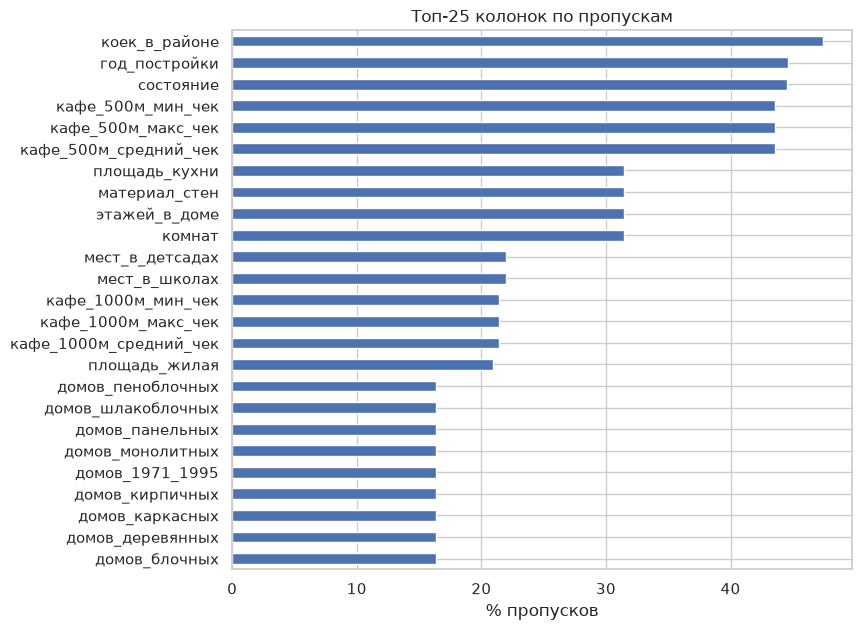

In [69]:
na = train.isna().mean().sort_values(ascending=False) * 100
na = na[na > 0]
print(f'Колонок с пропусками: {len(na)} из {train.shape[1]}')

na.head(25).plot(kind='barh', figsize=(8, 7))
plt.gca().invert_yaxis()
plt.xlabel('% пропусков')
plt.title('Топ-25 колонок по пропускам')
plt.show()

## Шаг 4. Целевая переменная — `цена`

count         30,471
mean       7,123,035
std        4,780,111
min          100,000
25%        4,740,002
50%        6,274,411
75%        8,300,000
max      111,111,112
Name: цена, dtype: str


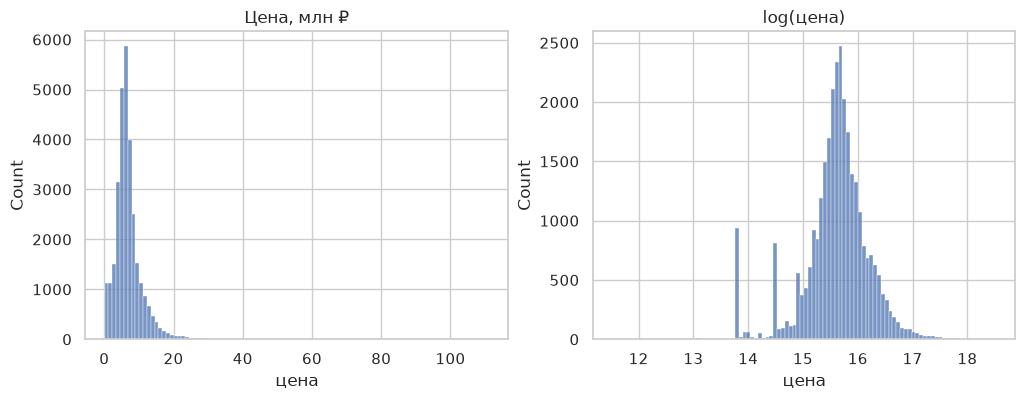

In [70]:
print(train['цена'].describe().apply(lambda x: f'{x:,.0f}'))

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(train['цена'] / 1e6, bins=100, ax=ax[0])
ax[0].set_title('Цена, млн ₽')
sns.histplot(np.log1p(train['цена']), bins=100, ax=ax[1])
ax[1].set_title('log(цена)')
plt.show()

In [71]:
# Подозрительно «круглые» дешёвые цены
for p in [1_000_000, 2_000_000, 3_000_000]:
    print(f'цена == {p:,}: {(train['цена'] == p).sum()} сделок')

цена == 1,000,000: 747 сделок
цена == 2,000,000: 757 сделок
цена == 3,000,000: 332 сделок


## Шаг 5. Ключевые признаки

тип_сделки
Investment       19448
OwnerOccupier    11023
Name: count, dtype: int64


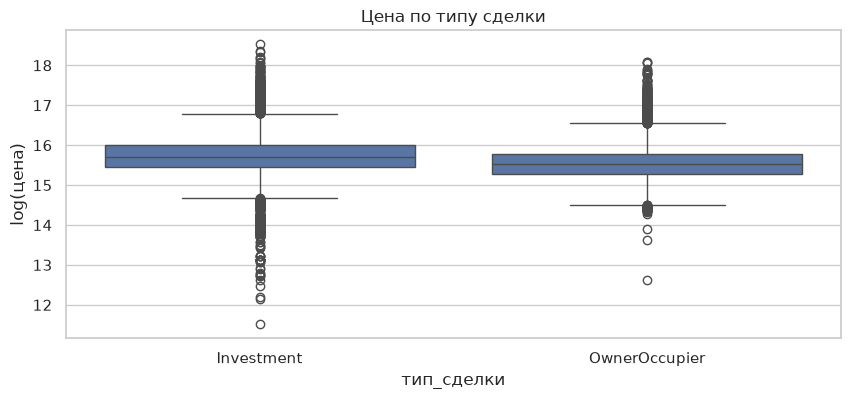

In [72]:
# Тип сделки: инвестиция (вторичка/перепродажа) или собственное жильё (часто новостройки)
print(train['тип_сделки'].value_counts(dropna=False))

sns.boxplot(data=train, x='тип_сделки', y=np.log1p(train['цена']))
plt.ylabel('log(цена)')
plt.title('Цена по типу сделки')
plt.show()

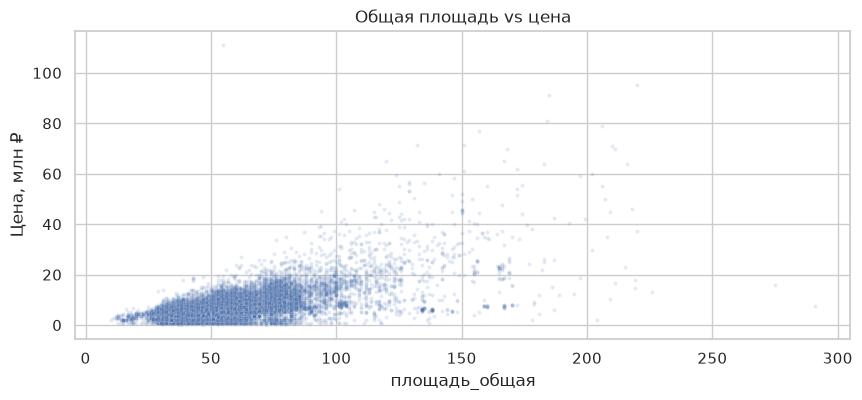

In [73]:
# Площадь vs цена (обрежем явные выбросы площади для наглядности)
d = train[train['площадь_общая'].between(10, 300)]
sns.scatterplot(data=d, x='площадь_общая', y=d['цена'] / 1e6, alpha=0.15, s=8)
plt.ylabel('Цена, млн ₽')
plt.title('Общая площадь vs цена')
plt.show()

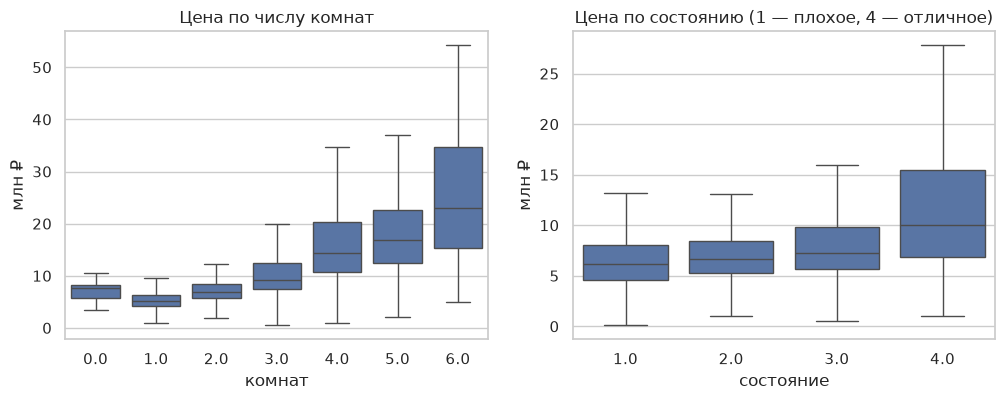

In [74]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
sns.boxplot(data=train[train['комнат'].between(0, 6)], x='комнат',
            y=train['цена'] / 1e6, ax=ax[0], showfliers=False)
ax[0].set_title('Цена по числу комнат')
ax[0].set_ylabel('млн ₽')
sns.boxplot(data=train[train['состояние'].between(1, 4)], x='состояние',
            y=train['цена'] / 1e6, ax=ax[1], showfliers=False)
ax[1].set_title('Цена по состоянию (1 — плохое, 4 — отличное)')
ax[1].set_ylabel('млн ₽')
plt.show()

## Шаг 6. Ошибки и выбросы в данных

In [75]:
checks = {
    'площадь_общая < 10 м²': (train['площадь_общая'] < 10).sum(),
    'площадь_общая > 300 м²': (train['площадь_общая'] > 300).sum(),
    'площадь_жилая > площадь_общая': (train['площадь_жилая'] > train['площадь_общая']).sum(),
    'площадь_кухни > площадь_общая': (train['площадь_кухни'] > train['площадь_общая']).sum(),
    'этаж > этажей_в_доме': (train['этаж'] > train['этажей_в_доме']).sum(),
    'год_постройки < 1800 или > 2020': ((train['год_постройки'] < 1800) | (train['год_постройки'] > 2020)).sum(),
    'состояние == 33 (опечатка)': (train['состояние'] == 33).sum(),
}
pd.Series(checks, name='кол-во строк').to_frame()

,кол-во строк
площадь_общая < 10 м²,29
площадь_общая > 300 м²,14
площадь_жилая > площадь_общая,37
площадь_кухни > площадь_общая,12
этаж > этажей_в_доме,1493
год_постройки < 1800 или > 2020,906
состояние == 33 (опечатка),1


In [76]:
# Какие странные значения в год_постройки
train.loc[(train['год_постройки'] < 1800) | (train['год_постройки'] > 2020), 'год_постройки'].value_counts().head(10)

год_постройки
0.0           530
1.0           368
3.0             2
20052009.0      1
20.0            1
4965.0          1
1691.0          1
215.0           1
71.0            1
Name: count, dtype: int64

## Шаг 7. Цена во времени

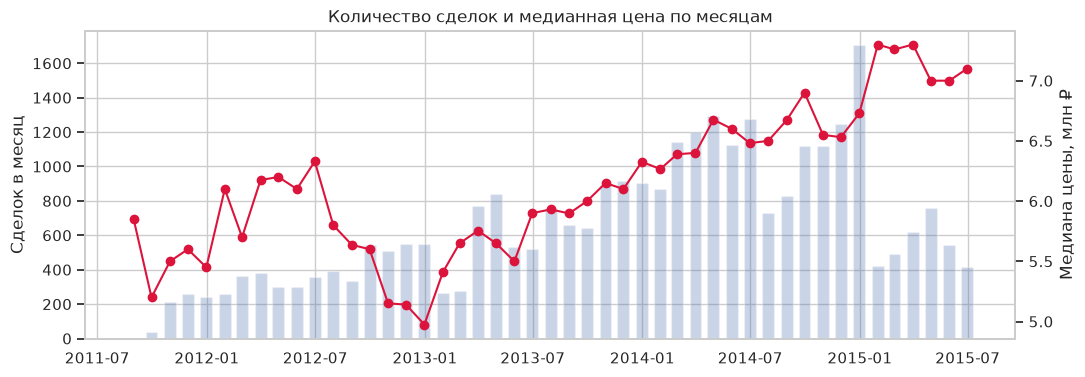

In [77]:
monthly = (train.set_index('дата')
                 .resample('ME')
                 .agg(price=('цена', 'median'), deals=('цена', 'size')))

fig, ax1 = plt.subplots(figsize=(12, 4))
ax1.bar(monthly.index, monthly.deals, width=20, alpha=0.3, label='сделок')
ax1.set_ylabel('Сделок в месяц')
ax2 = ax1.twinx()
ax2.plot(monthly.index, monthly.price / 1e6, color='crimson', marker='o', label='медиана цены')
ax2.set_ylabel('Медиана цены, млн ₽')
ax2.grid(False)
plt.title('Количество сделок и медианная цена по месяцам')
plt.show()

In [78]:
# Цена за квадратный метр — честнее сравнивать во времени
d = train[train['площадь_общая'].between(10, 300)].copy()
d['цена_м2'] = d['цена'] / d['площадь_общая']
d.groupby(d['дата'].dt.year)['цена_м2'].median().round(0).to_frame('медиана ₽/м²')

,медиана ₽/м²
дата,
2011,135934.0
2012,130405.0
2013,127378.0
2014,140000.0
2015,139545.0


## Шаг 8. Корреляции с ценой

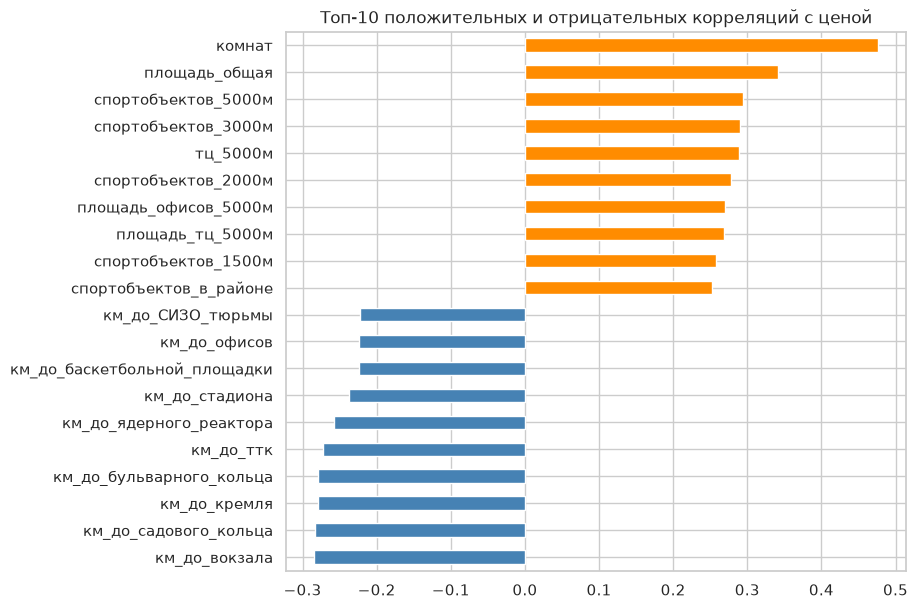

In [79]:
num = train.select_dtypes('number').drop(columns=['id_сделки'])
corr = num.corr()['цена'].drop('цена').sort_values()

top = pd.concat([corr.head(10), corr.tail(10)])
top.plot(kind='barh', figsize=(8, 7),
         color=['steelblue' if v < 0 else 'darkorange' for v in top])
plt.title('Топ-10 положительных и отрицательных корреляций с ценой')
plt.show()

## Шаг 9. Районы (`район`)

Районов: 146


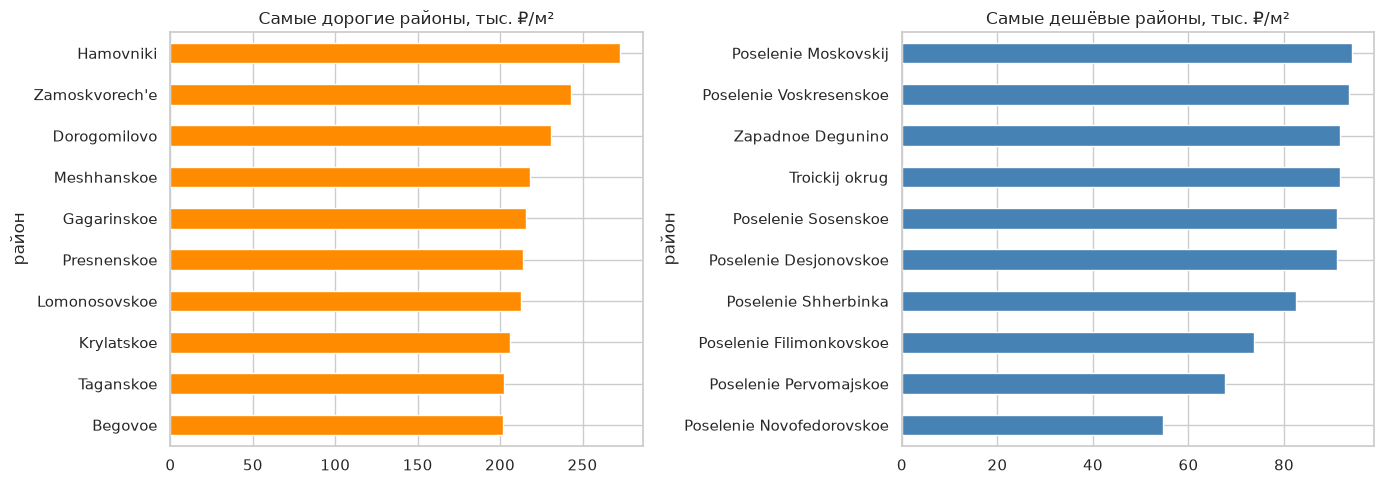

In [80]:
print('Районов:', train['район'].nunique())

d = train[train['площадь_общая'].between(10, 300)].copy()
d['цена_м2'] = d['цена'] / d['площадь_общая']
by_area = d.groupby('район').agg(deals=('id_сделки', 'size'), цена_м2=('цена_м2', 'median'))
by_area = by_area[by_area.deals >= 50].sort_values('цена_м2')

fig, ax = plt.subplots(1, 2, figsize=(14, 5))
(by_area['цена_м2'].tail(10) / 1000).plot(kind='barh', ax=ax[0], color='darkorange')
ax[0].set_title('Самые дорогие районы, тыс. ₽/м²')
(by_area['цена_м2'].head(10) / 1000).plot(kind='barh', ax=ax[1], color='steelblue')
ax[1].set_title('Самые дешёвые районы, тыс. ₽/м²')
plt.tight_layout()
plt.show()

In [81]:
# Где больше всего сделок
train['район'].value_counts().head(10)

район
Poselenie Sosenskoe         1776
Nekrasovka                  1611
Poselenie Vnukovskoe        1372
Poselenie Moskovskij         925
Poselenie Voskresenskoe      713
Mitino                       679
Tverskoe                     678
Krjukovo                     518
Mar'ino                      508
Poselenie Filimonkovskoe     496
Name: count, dtype: int64

## Шаг 10. Макроэкономика

В `macro.csv` 100 показателей на каждый день. Берём три самых понятных:
- `курс_доллара` — курс доллара в рублях
- `нефть_urals` — цена нефти Urals, $ за баррель (от неё сильно зависит рубль)
- `ставка_ипотеки` — средняя ставка по ипотеке, %

Полное описание всех 100 колонок — в `data/data_dictionary.txt`.

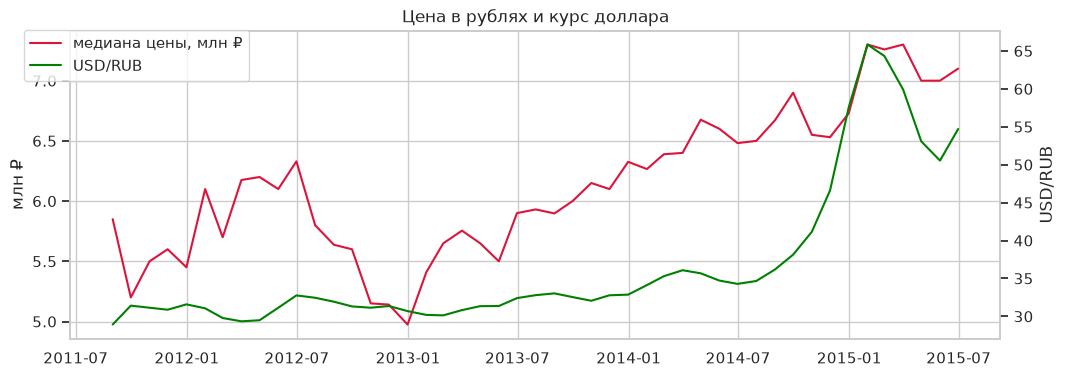

In [82]:
# Присоединяем макро-данные по дате сделки
df = train.merge(macro[['дата', 'курс_доллара', 'нефть_urals', 'ставка_ипотеки']],
                 on='дата', how='left')

m = df.set_index('дата').resample('ME').agg(
    price=('цена', 'median'), курс_доллара=('курс_доллара', 'mean'), mortgage=('ставка_ипотеки', 'mean'))

fig, ax1 = plt.subplots(figsize=(12, 4))
ax1.plot(m.index, m.price / 1e6, color='crimson', label='медиана цены, млн ₽')
ax1.set_ylabel('млн ₽')
ax2 = ax1.twinx()
ax2.plot(m.index, m['курс_доллара'], color='green', label='USD/RUB')
ax2.set_ylabel('USD/RUB')
ax2.grid(False)
fig.legend(loc='upper left', bbox_to_anchor=(0.08, 0.9))
plt.title('Цена в рублях и курс доллара')
plt.show()

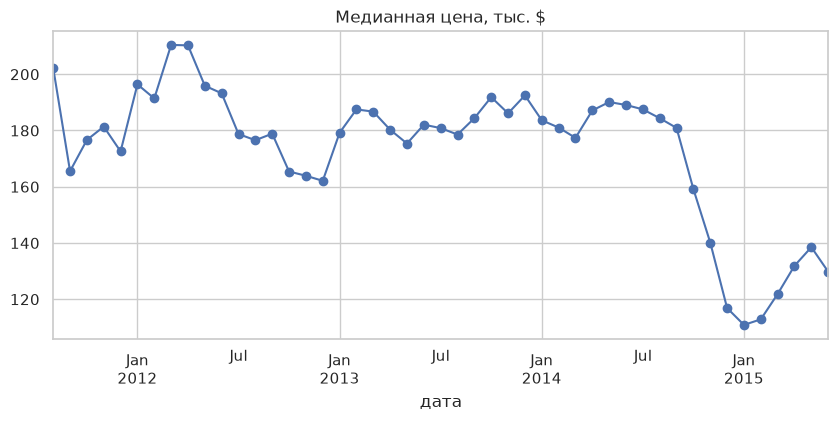

In [83]:
# А если посчитать цену в долларах?
m['price_usd'] = m.price / m['курс_доллара']
(m['price_usd'] / 1000).plot(marker='o', title='Медианная цена, тыс. $')
plt.show()

## Шаг 11. Выводы

1. **Данные:** 30 471 сделка, 292 признака, период авг 2011 – июн 2015. Большинство признаков — про район (школы, кафе, расстояния), а не про саму квартиру.
2. **Пропуски:** в 51 колонке. У `год_постройки`, `состояние` ~45% пропусков, у `этажей_в_доме`, `комнат`, `площадь_кухни` ~31% (в ранних сделках их вообще не заполняли).
3. **Цена:** медиана ~6.3 млн ₽, распределение с длинным хвостом вправо → для модели лучше брать `log(цена)`.
4. **Подозрительные цены:** ~1 800 сделок ровно по 1, 2 и 3 млн ₽ — похоже на заниженные цены в договорах. Это шум для модели.
5. **Ошибки в данных:** `год_постройки` = 0, 1, 20052009; `состояние` = 33; `площадь_жилая > площадь_общая`; `этаж > этажей_в_доме` в ~1 500 строках. Перед моделью нужна чистка.
6. **Что влияет на цену:** площадь и число комнат (корреляция +0.34 и +0.48), инфраструктура рядом (спорт, ТРЦ) и расстояние до центра (чем дальше от Кремля — тем дешевле).
7. **Районы:** самые дорогие — центр (Хамовники ~270 тыс ₽/м²), самые дешёвые — «Поселения» Новой Москвы (55–95 тыс ₽/м²). Но именно там больше всего сделок (новостройки).
8. **Время и макро:** в рублях цена росла, но в долларах в конце 2014 упала почти вдвое — это обвал рубля. В декабре 2014 был пик сделок (люди спасали сбережения в квартирах), потом спад.

**Что дальше:** почистить ошибки → взять `log(price)` → добавить признаки `цена_м2`, год/месяц, возраст дома → простая модель (Linear Regression → Random Forest / XGBoost).